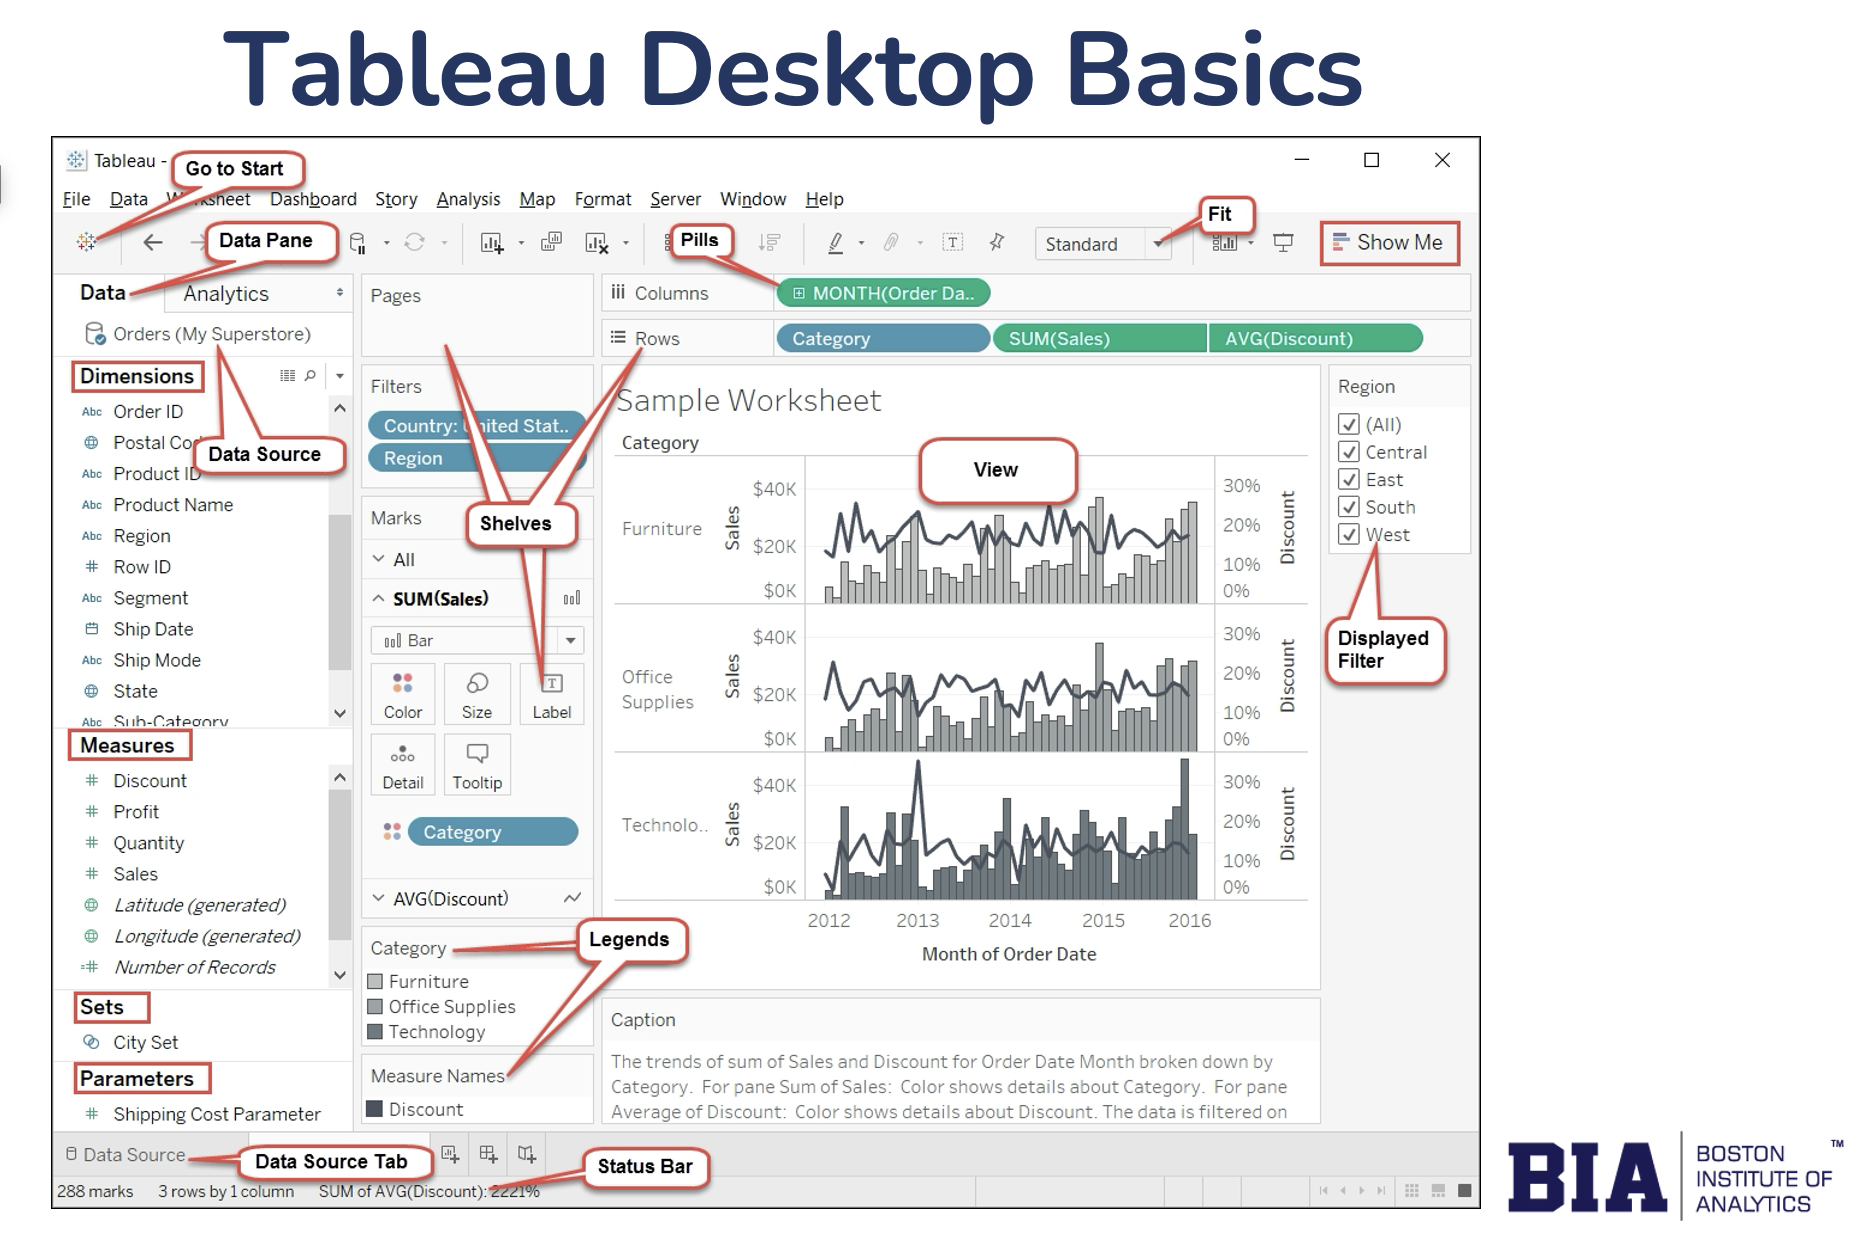

In [ ]:
! pip install mysql-connector-python  sqlalchemy python-dotenv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.0/20.0 MB 1.2 MB/s eta 0:00:001.2 MB/s eta 0:00:010m

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
# %pip install mysql-connector-python python-dotenv

# Test The connection to the MySQL database

In [1]:
import os
import mysql.connector
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv())

# connect to the MySQL database
conn = mysql.connector.connect(
        host=os.environ.get("MYSQL_HOST"),
        user=os.environ.get("MYSQL_USER"),
        password=os.environ.get("MYSQL_PASSWORD"),
        # database=os.environ.get("MYSQL_DATABASE")
)
# print connection status
print("Connected:", conn.is_connected())

# create a cursor object to interact with the database
cursor = conn.cursor()

# create the database if it doesn't exist and show it
cursor.execute("CREATE DATABASE IF NOT EXISTS python_demo")

# show the databases that match the pattern 'python%'
cursor.execute("SHOW DATABASES LIKE 'python%'")

# fetch and print the results of the previous query
print(cursor.fetchall())

# close the connection to the database
conn.close()
cursor.close()

Connected: True
[('python_demo',)]


True

# Part 0 Setup

`pip install pandas xlrd mysql-connector-python python-dotenv`

.env
```python
MYSQL_HOST=localhost
MYSQL_USER=your_mysql_username
MYSQL_PASSWORD=your_mysql_password
```


**Watch out**: Add .env to your .gitignore so the password never reaches GitHub. Put the notebook, the
.env file and Sample - Superstore.xls in the same folder.

# Part 1 Read the Orders sheet

In [6]:
import pandas as pd
excel = pd.ExcelFile("sample_superstore.xls")
print(excel.sheet_names)
orders = pd.read_excel(excel, sheet_name="Orders")
print(orders.shape)

['Orders', 'Returns', 'People']
(9994, 21)


In [8]:
orders.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


# Part 2 Clean and check the data

In [9]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

# Part 3 Connect and create the database tableau_data

In [10]:
import os
import mysql.connector
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv())
conn = mysql.connector.connect(
host=os.environ.get("MYSQL_HOST"),
user=os.environ.get("MYSQL_USER"),
password=os.environ.get("MYSQL_PASSWORD"),
)
print("Connected:", conn.is_connected())
cursor = conn.cursor()
cursor.execute("""
CREATE DATABASE IF NOT EXISTS tableau_data
CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci
""")
cursor.execute("SHOW DATABASES LIKE 'tableau%'")
print(cursor.fetchall())
cursor.execute("USE tableau_data")

Connected: True
[('tableau_data',)]


# Part 4 Create the table orders with the Excel column names

MySQL allows spaces and hyphens in column names, such as Order ID and Sub-Category, if each name is
wrapped in backticks (the key to the left of 1), as in the cell below. Keeping the Excel names means Tableau
shows the same field names your learners already know. Remember the backticks in every later query that uses
these names.

In [12]:
cursor.execute("DROP TABLE IF EXISTS orders")
cursor.execute("""
CREATE TABLE orders (
`Row ID` INT NOT NULL PRIMARY KEY,
`Order ID` VARCHAR(20) NOT NULL,
`Order Date` DATE NOT NULL,
`Ship Date` DATE NOT NULL,
`Ship Mode` VARCHAR(20) NOT NULL,
`Customer ID` VARCHAR(10) NOT NULL,
`Customer Name` VARCHAR(50) NOT NULL,
`Segment` VARCHAR(20) NOT NULL,
`Country` VARCHAR(30) NOT NULL,
`City` VARCHAR(40) NOT NULL,
`State` VARCHAR(30) NOT NULL,
`Postal Code` VARCHAR(10) NOT NULL,
`Region` VARCHAR(10) NOT NULL,
`Product ID` VARCHAR(20) NOT NULL,
`Category` VARCHAR(20) NOT NULL,
`Sub-Category` VARCHAR(20) NOT NULL,
`Product Name` VARCHAR(255) NOT NULL,
`Sales` DECIMAL(12, 4) NOT NULL,
`Quantity` INT NOT NULL,
`Discount` DECIMAL(4, 2) NOT NULL,
`Profit` DECIMAL(12, 4) NOT NULL
)
""")
cursor.execute("DESCRIBE orders")


In [13]:
for field, col_type, null, key, default, extra in cursor.fetchall():
    print(f"{field:<14} {col_type:<15} {key}")

Row ID         int             PRI
Order ID       varchar(20)     
Order Date     date            
Ship Date      date            
Ship Mode      varchar(20)     
Customer ID    varchar(10)     
Customer Name  varchar(50)     
Segment        varchar(20)     
Country        varchar(30)     
City           varchar(40)     
State          varchar(30)     
Postal Code    varchar(10)     
Region         varchar(10)     
Product ID     varchar(20)     
Category       varchar(20)     
Sub-Category   varchar(20)     
Product Name   varchar(255)    
Sales          decimal(12,4)   
Quantity       int             
Discount       decimal(4,2)    
Profit         decimal(12,4)   


# Part 5 Insert the cleaned data


In [14]:
columns = ", ".join(f"`{col}`" for col in orders.columns)
placeholders = ", ".join(["%s"] * len(orders.columns))
insert_sql = f"INSERT INTO orders ({columns}) VALUES ({placeholders})"
print(insert_sql[:120], "...")
rows = orders.astype(object).values.tolist()
print(rows[0])

INSERT INTO orders (`Row ID`, `Order ID`, `Order Date`, `Ship Date`, `Ship Mode`, `Customer ID`, `Customer Name`, `Segme ...
[1, 'CA-2016-152156', Timestamp('2016-11-08 00:00:00'), Timestamp('2016-11-11 00:00:00'), 'Second Class', 'CG-12520', 'Claire Gute', 'Consumer', 'United States', 'Henderson', 'Kentucky', 42420, 'South', 'FUR-BO-10001798', 'Furniture', 'Bookcases', 'Bush Somerset Collection Bookcase', 261.96, 2, 0.0, 41.9136]


The INSERT is built from the DataFrame's own column names, so it always matches the table.
astype(object).values.tolist() turns each row into plain Python values, which the connector can send (it
cannot send some NumPy number types).

In [15]:
# Add the cleaned data to the orders table in batches of 1000
batch_size = 1000
for start in range(0, len(rows), batch_size):
    cursor.executemany(insert_sql, rows[start:start + batch_size])
conn.commit()


In [16]:
cursor.execute("SELECT COUNT(*) FROM orders")
print("Rows in tableau_data.orders:", cursor.fetchone()[0])

Rows in tableau_data.orders: 9994
